In [1]:
#N1: imports + load CIFAR-100 (pickled batches: meta, train, test)

import pickle
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import time
import matplotlib.pyplot as plt
BASE = '/kaggle/input/datasets/mtalhasohail/cifar-100'

def unpickle(path):
    with open(path, 'rb') as f:
        return pickle.load(f, encoding='latin1')

meta  = unpickle(f'{BASE}/meta')
train = unpickle(f'{BASE}/train')
test  = unpickle(f'{BASE}/test')

fine_names = meta['fine_label_names']          # 100 names, index = fine label

x_train_all = train['data']                     # [50000, 3072] uint8, R-block+G-block+B-block per row (converted to 784 in N2)
y_train_all = np.array(train['fine_labels'])     # [50000] values 0-99

x_test_all  = test['data']                       # [10000, 3072]
y_test_all  = np.array(test['fine_labels'])       # [10000]

print(f"train: {x_train_all.shape}   test: {x_test_all.shape}")
print(f"fine labels: {y_train_all.min()} to {y_train_all.max()}  (100 classes total)")


train: (50000, 3072)   test: (10000, 3072)
fine labels: 0 to 99  (100 classes total)


/tmp/ipykernel_179/573483402.py:10: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb, 'RGB').convert('L')


after conversion  train: (50000, 784)   test: (10000, 784)


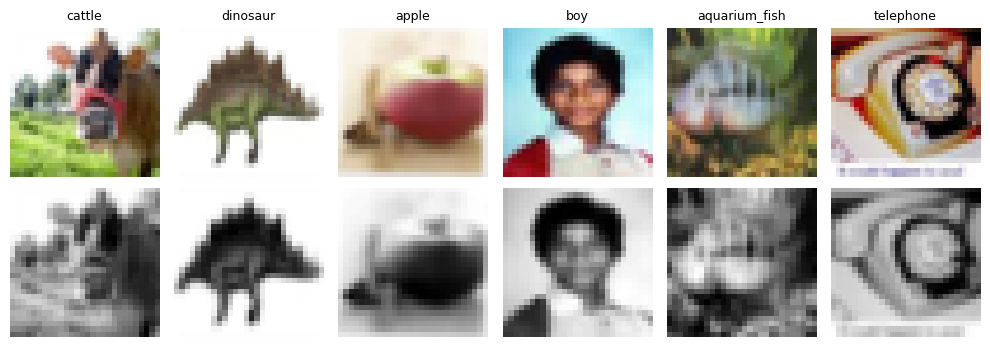

In [2]:
#N2: convert CIFAR-100 to 28x28 grayscale 


from PIL import Image

def to_gray28(rows):
    out = np.empty((len(rows), 784), dtype=np.uint8)
    for i, r in enumerate(rows):
        rgb = r.reshape(3, 32, 32).transpose(1, 2, 0)              # 32x32x3
        img = Image.fromarray(rgb, 'RGB').convert('L')             
        img = img.resize((28, 28), Image.BILINEAR)                  # 32x32 -> 28x28 (whole image, no cropping)
        out[i] = np.asarray(img, dtype=np.uint8).reshape(-1)
    return out

x_train_color = x_train_all                     
x_train_all   = to_gray28(x_train_all)          
x_test_all    = to_gray28(x_test_all)           # [10000, 784]
print(f"after conversion  train: {x_train_all.shape}   test: {x_test_all.shape}")

# visual check: top = original 32x32 color, bottom = 28x28 grayscale
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for k in range(6):
    axes[0, k].imshow(x_train_color[k].reshape(3, 32, 32).transpose(1, 2, 0))
    axes[0, k].set_title(fine_names[y_train_all[k]], fontsize=9)
    axes[1, k].imshow(x_train_all[k].reshape(28, 28), cmap='gray')
    axes[0, k].axis('off'); axes[1, k].axis('off')
plt.tight_layout(); plt.show()
del x_train_color


In [3]:
#N3: defining 6 problems - 5 CIFAR-100 fine classes per group

SCRIPT_NAMES = ["P1_aquatic",  "P2_fish",   "P3_flowers",
                "P4_containers", "P5_produce", "P6_devices"]

GROUP_CLASS_NAMES = [
    ["beaver", "dolphin", "otter", "seal", "whale"],                     # P1
    ["aquarium_fish", "flatfish", "ray", "shark", "trout"],              # P2
    ["orchid", "poppy", "rose", "sunflower", "tulip"],                   # P3
    ["bottle", "bowl", "can", "cup", "plate"],                           # P4
    ["apple", "mushroom", "orange", "pear", "sweet_pepper"],             # P5
    ["clock", "keyboard", "lamp", "telephone", "television"],            # P6
]

name_to_fine = {n: i for i, n in enumerate(fine_names)}
GROUP_LABELS = [[name_to_fine[n] for n in grp] for grp in GROUP_CLASS_NAMES]

for names, labels in zip(GROUP_CLASS_NAMES, GROUP_LABELS):
    print(list(zip(names, labels)))

print("\n6 problems, 5 classes each, 30 CIFAR-100 fine classes used out of 100")


[('beaver', 4), ('dolphin', 30), ('otter', 55), ('seal', 72), ('whale', 95)]
[('aquarium_fish', 1), ('flatfish', 32), ('ray', 67), ('shark', 73), ('trout', 91)]
[('orchid', 54), ('poppy', 62), ('rose', 70), ('sunflower', 82), ('tulip', 92)]
[('bottle', 9), ('bowl', 10), ('can', 16), ('cup', 28), ('plate', 61)]
[('apple', 0), ('mushroom', 51), ('orange', 53), ('pear', 57), ('sweet_pepper', 83)]
[('clock', 22), ('keyboard', 39), ('lamp', 40), ('telephone', 86), ('television', 87)]

6 problems, 5 classes each, 30 CIFAR-100 fine classes used out of 100


In [4]:
#N4: building 6 datasets

train_datasets = []
test_datasets  = []

for m in range(6):
    labels = GROUP_LABELS[m]

    mask     = np.isin(y_train_all, labels)
    x_tr     = x_train_all[mask].astype(np.float32).copy()
    y_tr_raw = y_train_all[mask].copy()
    y_tr     = np.zeros(len(y_tr_raw), dtype=np.int64)
    for new_label, old_label in enumerate(labels):
        y_tr[y_tr_raw == old_label] = new_label

    mask     = np.isin(y_test_all, labels)
    x_te     = x_test_all[mask].astype(np.float32).copy()
    y_te_raw = y_test_all[mask].copy()
    y_te     = np.zeros(len(y_te_raw), dtype=np.int64)
    for new_label, old_label in enumerate(labels):
        y_te[y_te_raw == old_label] = new_label

    x_tr = torch.tensor(x_tr, dtype=torch.float32)
    x_te = torch.tensor(x_te, dtype=torch.float32)
    y_tr = torch.tensor(y_tr, dtype=torch.long)
    y_te = torch.tensor(y_te, dtype=torch.long)

    mean = x_tr.mean()
    std  = x_tr.std()
    x_tr = (x_tr - mean) / std
    x_te = (x_te - mean) / std

    train_datasets.append(TensorDataset(x_tr, y_tr))
    test_datasets.append(TensorDataset(x_te, y_te))

    print(f"{SCRIPT_NAMES[m]}: train {len(x_tr):5d}  test {len(x_te):4d}  "
          f"mean {x_tr.mean():.2f}  std {x_tr.std():.2f}")


P1_aquatic: train  2500  test  500  mean -0.00  std 1.00
P2_fish: train  2500  test  500  mean 0.00  std 1.00
P3_flowers: train  2500  test  500  mean -0.00  std 1.00
P4_containers: train  2500  test  500  mean -0.00  std 1.00
P5_produce: train  2500  test  500  mean 0.00  std 1.00
P6_devices: train  2500  test  500  mean 0.00  std 1.00


In [5]:
#N5: DataLoaders + settings

BATCH_SIZE = 32
train_loaders = [DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True) for ds in train_datasets]
test_loaders  = [DataLoader(ds, batch_size=256, shuffle=False)       for ds in test_datasets]

def infinite(loader):
    while True:
        for batch in loader:
            yield batch

DEVICE          = 'cuda' if torch.cuda.is_available() else 'cpu'
INPUT_SIZE      = 784          
HIDDEN_SIZE     = 128           
NUM_G_SETS      = 4
NUM_PROBLEMS    = 6
CLASSES_PER     = 5             # was 7 for EMNIST, now 5 classes per CIFAR-100 group
TOTAL_CLASSES   = NUM_PROBLEMS * CLASSES_PER   # 30

LEARNING_RATE   = 0.01
MOMENTUM        = 0.9
NUM_EPOCHS      = 40
STEPS_PER_EPOCH = 78            # 2,500 train images per group / 32 = 78 (one full pass)
N_RUNS          = 30
EVAL_EVERY      = 5
PRINT_EVERY     = 5
a               = 0             

B_CONFIGS = torch.tensor([
    [1,1,a,a],
    [1,a,1,a],
    [1,a,a,1],
    [a,1,1,a],
    [a,1,a,1],
    [a,a,1,1],
], dtype=torch.float32).to(DEVICE)

print(f"Device: {DEVICE}")
print(f"Runs: {N_RUNS}  Epochs: {NUM_EPOCHS}  Steps/epoch: {STEPS_PER_EPOCH}")
print(f"Both train loss and test loss = avg CE per problem )")


Device: cuda
Runs: 30  Epochs: 40  Steps/epoch: 78
Both train loss and test loss = avg CE per problem )


In [6]:
#N9:MODEL 4: COMPOUND SYNAPSE
# 4 G sets hidden + 4 G sets output. Same b picks 2-of-4 in both.
# 4 * [784*128 + 128*5] = 4 * 100,992 = 403,968 parameters
# (architecture identical to the EMNIST version only classes changed

accs_compound    = []
trloss_compound  = []
teloss_compound  = []
tracc_compound   = []   # train accuracy per run

print("Training COMPOUND SYNAPSE on CIFAR-100 (6 groups x 5 classes)...")
print(f"{'Run':>4} {'Ep':>4} | {'Tr loss':>8} {'Te loss':>8} | {'Tr acc':>7} {'Te acc':>7} | "
      f"{'aquat':>6} {'fish':>6} {'flowr':>6} {'contnr':>6} {'produc':>6} {'devic':>6}")
print("-" * 92)
t0 = time.time()

for run in range(N_RUNS):

    Ghid_comp = nn.Parameter(torch.empty(4, HIDDEN_SIZE, INPUT_SIZE, device=DEVICE))
    Gout_comp = nn.Parameter(torch.empty(4, CLASSES_PER, HIDDEN_SIZE, device=DEVICE))
    for n in range(4):
        nn.init.kaiming_normal_(Ghid_comp.data[n], mode="fan_in", nonlinearity="relu")
        nn.init.kaiming_normal_(Gout_comp.data[n], mode="fan_in", nonlinearity="relu")

    optimizer_comp = torch.optim.SGD([Ghid_comp, Gout_comp], lr=LEARNING_RATE, momentum=MOMENTUM)
    inf_iters_comp = [infinite(loader) for loader in train_loaders]   
    last_tr_loss   = 0.0

    for epoch in range(NUM_EPOCHS):
        epoch_loss = 0.0
        tr_correct = tr_total = 0
        for step in range(STEPS_PER_EPOCH):
            optimizer_comp.zero_grad()
            total_loss = torch.zeros((), device=DEVICE)
            for m in range(6):
                x, y = next(inf_iters_comp[m])
                x, y = x.to(DEVICE), y.to(DEVICE)
                b    = B_CONFIGS[m]

                scale = (2 + 2*a**2) ** 0.5     # a=1 gives 2.0, a=0 gives 1.414
                W    = torch.einsum('n,nhi->hi', b, Ghid_comp)/scale
                Wout = torch.einsum('n,noh->oh', b, Gout_comp)/scale
                h    = F.relu(x @ W.T)
                out  = h @ Wout.T
                total_loss = total_loss + F.cross_entropy(out, y)
                tr_correct += (out.argmax(1) == y).sum().item()
                tr_total   += y.size(0)
            total_loss.backward()
            optimizer_comp.step()
            epoch_loss += total_loss.item()

        avg_tr       = epoch_loss / STEPS_PER_EPOCH / NUM_PROBLEMS
        last_tr_loss = avg_tr
        tr_acc       = tr_correct / tr_total * 100

        if (epoch + 1) % EVAL_EVERY == 0:
            ep_accs    = []
            ep_te_loss = 0.0
            with torch.no_grad():
                for m in range(6):
                    correct = total = 0
                    m_loss  = n_bat = 0.0
                    b    = B_CONFIGS[m]

                    scale = (2 + 2*a**2) ** 0.5
                    W    = torch.einsum('n,nhi->hi', b, Ghid_comp)/scale
                    Wout = torch.einsum('n,noh->oh', b, Gout_comp)/scale
                    for x, y in test_loaders[m]:
                        x, y    = x.to(DEVICE), y.to(DEVICE)
                        out     = F.relu(x @ W.T) @ Wout.T
                        correct += (out.argmax(1) == y).sum().item()
                        total   += y.size(0)
                        m_loss  += F.cross_entropy(out, y).item()
                        n_bat   += 1
                    ep_accs.append(correct / total * 100)
                    ep_te_loss += m_loss / n_bat
            avg_te = ep_te_loss / NUM_PROBLEMS

            if (run + 1) % PRINT_EVERY == 0:
                acc_str = " ".join(f"{acc:6.1f}" for acc in ep_accs)
                print(f"{run+1:4d} {epoch+1:4d} | {avg_tr:8.4f} {avg_te:8.4f} | "
                      f"{tr_acc:6.2f}% {np.mean(ep_accs):6.2f}% | {acc_str}")

    run_accs    = []
    run_te_loss = 0.0
    with torch.no_grad():
        for m in range(6):
            correct = total = 0
            m_loss  = n_bat = 0.0
            b    = B_CONFIGS[m]

            scale = (2 + 2*a**2) ** 0.5
            W    = torch.einsum('n,nhi->hi', b, Ghid_comp)/scale
            Wout = torch.einsum('n,noh->oh', b, Gout_comp)/scale
            for x, y in test_loaders[m]:
                x, y    = x.to(DEVICE), y.to(DEVICE)
                out     = F.relu(x @ W.T) @ Wout.T
                correct += (out.argmax(1) == y).sum().item()
                total   += y.size(0)
                m_loss  += F.cross_entropy(out, y).item()
                n_bat   += 1
            run_accs.append(correct / total * 100)
            run_te_loss += m_loss / n_bat

    accs_compound.append(run_accs)
    trloss_compound.append(last_tr_loss)
    tracc_compound.append(tr_acc)
    teloss_compound.append(run_te_loss / NUM_PROBLEMS)

    if (run + 1) % PRINT_EVERY == 0:
        print(f"  \u2192 run {run+1}  train acc {tr_acc:.2f}%  test acc {np.mean(run_accs):.2f}%  "
              f"tr loss {last_tr_loss:.4f}  te loss {run_te_loss/NUM_PROBLEMS:.4f}  [{time.time()-t0:.0f}s]\n")

print(f"\nCOMPOUND DONE:  "
      f"train acc {np.mean(tracc_compound):.2f}% \u00B1 {np.std(tracc_compound):.2f}%  |  "
      f"test acc {np.mean([np.mean(r) for r in accs_compound]):.2f}% \u00B1 "
      f"{np.std([np.mean(r) for r in accs_compound]):.2f}%  |  "
      f"train loss {np.mean(trloss_compound):.4f}  test loss {np.mean(teloss_compound):.4f}\n")


Training COMPOUND SYNAPSE on CIFAR-100 (6 groups x 5 classes)...
 Run   Ep |  Tr loss  Te loss |  Tr acc  Te acc |  aquat   fish  flowr contnr produc  devic
--------------------------------------------------------------------------------------------
   5    5 |   1.1935   1.4767 |  53.58%  43.77% |   29.0   54.2   33.2   56.4   41.2   48.6
   5   10 |   1.0424   1.7078 |  61.84%  42.33% |   32.8   50.0   31.2   53.6   41.2   45.2
   5   15 |   0.9135   2.0805 |  68.03%  42.70% |   32.2   49.6   29.8   53.6   44.4   46.6
   5   20 |   0.7746   2.4252 |  73.41%  42.87% |   34.2   46.4   32.4   55.4   41.2   47.6
   5   25 |   0.7865   2.6624 |  75.43%  43.70% |   31.6   50.8   33.2   53.8   40.6   52.2
   5   30 |   0.6637   3.1584 |  79.31%  41.17% |   30.4   50.0   26.0   54.0   37.4   49.2
   5   35 |   0.6969   3.4172 |  79.52%  42.67% |   31.6   46.4   33.2   56.2   42.2   46.4
   5   40 |   0.6060   3.8419 |  82.54%  42.50% |   29.6   51.2   31.4   55.8   41.4   45.6
  → run 5  tra